In [1]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [ ]:
Kandi=pd.read_csv("data/Kandi_final.csv")

Parakou=pd.read_csv("data/PARAKOU.csv")

<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:3: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:3: SyntaxWarning: invalid escape sequence '\P'
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_12132\2163015442.py:1: SyntaxWarning: invalid escape sequence '\K'
  Kandi=pd.read_csv("data\Kandi_final.csv")
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_12132\2163015442.py:3: SyntaxWarning: invalid escape sequence '\P'
  Parakou=pd.read_csv("data\PARAKOU.csv")


In [3]:
Kandi.columns

Index(['Lieu', 'annee', 'mois', 'jour', 'Pression', 'Temperature_Max',
       'Temperature_Min', 'Humidite', 'Vitesse_Vent', 'Pluviometrie'],
      dtype='str')

In [ ]:
liste_varia=['Pression', 'Temperature_Max','Temperature_Min', 'Humidite', 'Vitesse_Vent',"Lieu"]
def creation(data):
    df=data.copy()
    for i in [1,2,3,5,6,7,30]:
        df[f"Pluviometrie_lag{i}"]=df["Pluviometrie"].shift(i)
    for feat in ['Pression', 'Temperature_Max','Temperature_Min', 'Humidite', 'Vitesse_Vent']:
        df[f"{feat}_lag{1}"]=df[feat].shift(1)
    for j in [4,7,30]:
        df[f"Pluviometrie_moy{j}"]=df["Pluviometrie"].shift(1).rolling(j).mean()
    df=df.dropna(axis=0)
    df.index=range(len(df))
    return df.drop(liste_varia,axis=1)
        

In [5]:
Kandi=creation(Kandi)
Parakou=creation(Parakou)

In [6]:
Kandi_y_train=Kandi[Kandi.annee<2024]["Pluviometrie"]
Kandi_y_test=Kandi[2024<=Kandi.annee]["Pluviometrie"]

Kandi_X_train=Kandi[Kandi.annee<2024].drop(["Pluviometrie"],axis=1)
Kandi_X_test=Kandi[2024<=Kandi.annee].drop(["Pluviometrie"],axis=1)

Parakou_y_train=Parakou[Parakou.annee<2024]["Pluviometrie"]
Parakou_y_test=Parakou[2024<=Parakou.annee]["Pluviometrie"]

Parakou_X_train=Parakou[Parakou.annee<2024].drop(["Pluviometrie"],axis=1)
Parakou_X_test=Parakou[2024<=Parakou.annee].drop(["Pluviometrie"],axis=1)

Kandi_X_train

,annee,mois,jour,Pluviometrie_lag1,Pluviometrie_lag2,Pluviometrie_lag3,Pluviometrie_lag5,Pluviometrie_lag6,Pluviometrie_lag7,Pluviometrie_lag30,Pression_lag1,Temperature_Max_lag1,Temperature_Min_lag1,Humidite_lag1,Vitesse_Vent_lag1,Pluviometrie_moy4,Pluviometrie_moy7,Pluviometrie_moy30
0,2015,1,31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,978.3,36.2,16.7,26.0,1.4,0.0,0.0,0.0
1,2015,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,978.3,37.4,18.5,29.0,0.9,0.0,0.0,0.0
2,2015,2,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,977.7,37.5,19.3,27.0,1.3,0.0,0.0,0.0
3,2015,2,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,976.6,38.5,18.9,25.0,1.6,0.0,0.0,0.0
4,2015,2,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,976.5,39.7,20.2,26.0,1.6,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3251,2023,12,27,0.0,0.0,0.0,0.0,0.0,0.0,0.0,979.3,31.5,13.7,35.0,2.1,0.0,0.0,0.0
3252,2023,12,28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,979.4,32.7,14.1,26.0,2.6,0.0,0.0,0.0
3253,2023,12,29,0.0,0.0,0.0,0.0,0.0,0.0,0.0,980.2,34.0,16.9,31.0,2.3,0.0,0.0,0.0
3254,2023,12,30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,979.5,33.4,15.4,36.0,1.9,0.0,0.0,0.0


In [7]:
"""import sys
!"{sys.executable}" -m pip install xgboost"""

'import sys\n!"{sys.executable}" -m pip install xgboost'

In [8]:
def entrainement(X_train,y_train,X_test,y_test):
    model = XGBRegressor(objective="reg:squarederror",n_estimators=300,max_depth=6,learning_rate=0.05,random_state=42)
    model.fit(X_train,y_train)
    prediction=model.predict(X_test)
    return {"model":model,"prediction":prediction,"MAE":mean_absolute_error(y_test,prediction),"RMSE":np.sqrt(mean_squared_error(y_test,prediction))}

In [9]:
kd=entrainement(Kandi_X_train,Kandi_y_train,Kandi_X_test,Kandi_y_test)

In [10]:
pk=entrainement(Parakou_X_train,Parakou_y_train,Parakou_X_test,Parakou_y_test)

In [11]:
resultats=pd.concat([pd.DataFrame({"Station":["Kandi"],"MAE":kd["MAE"],"RMSE":kd["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"MAE":pk["MAE"],"RMSE":pk["RMSE"]})],axis=0)

resultats

,Station,MAE,RMSE
0,Kandi,4.551229,9.540730
0,Parakou,5.910202,11.865439


In [12]:
importance_Kandi = pd.DataFrame(
{
    "Variable":Kandi_X_train.columns,
    "Importance":
    kd["model"].feature_importances_
}
).sort_values(by='Importance')

importance_Kandi

,Variable,Importance
0,annee,0.030795
2,jour,0.039207
3,Pluviometrie_lag1,0.039296
12,Temperature_Min_lag1,0.042678
9,Pluviometrie_lag30,0.043774
10,Pression_lag1,0.043919
5,Pluviometrie_lag3,0.046533
14,Vitesse_Vent_lag1,0.048565
16,Pluviometrie_moy7,0.049170
11,Temperature_Max_lag1,0.049716


In [13]:
importance_Parakou = pd.DataFrame(
{
    "Variable":Parakou_X_train.columns,
    "Importance":
    pk["model"].feature_importances_
}
).sort_values(by='Importance')

importance_Parakou

,Variable,Importance
7,Pluviometrie_lag6,0.035502
0,annee,0.037493
12,Temperature_Min_lag1,0.040354
1,mois,0.041996
14,Vitesse_Vent_lag1,0.045256
10,Pression_lag1,0.051212
6,Pluviometrie_lag5,0.051701
2,jour,0.053377
8,Pluviometrie_lag7,0.053541
3,Pluviometrie_lag1,0.057756


In [14]:
from sklearn.model_selection import TimeSeriesSplit,RandomizedSearchCV,GridSearchCV
tscv = TimeSeriesSplit(n_splits=5)
def gridsech(X_train,y_train,X_test,y_test,param):
    model = XGBRegressor(objective="reg:squarederror",n_estimators=300,max_depth=6,learning_rate=0.05,random_state=42)
    grid=GridSearchCV(estimator=model,param_grid=param,scoring="neg_mean_absolute_error",verbose=2,cv=tscv)
    grid.fit(X_train,y_train)
    prediction=grid.predict(X_test)
    return {"grid":grid,"prediction":prediction,"MAE":mean_absolute_error(y_test,prediction),"RMSE":np.sqrt(mean_squared_error(y_test,prediction))}

In [15]:
import matplotlib.pyplot as plt
def model_final(X_train,y_train,X_test,y_test,max_deph):
    model = XGBRegressor(objective="reg:squarederror",n_estimators=50,max_depth=max_deph,learning_rate=0.1,random_state=42)
    model.fit(X_train,y_train)
    prediction=model.predict(X_test)
    plt.figure(figsize=(10,5))
    plt.plot(y_test.index,y_test,label="Test")
    plt.plot(y_test.index,prediction,label="Prediction")
    plt.legend()
    return {"grid":model,"prediction":prediction,"MAE":mean_absolute_error(y_test,prediction),"RMSE":np.sqrt(mean_squared_error(y_test,prediction))}

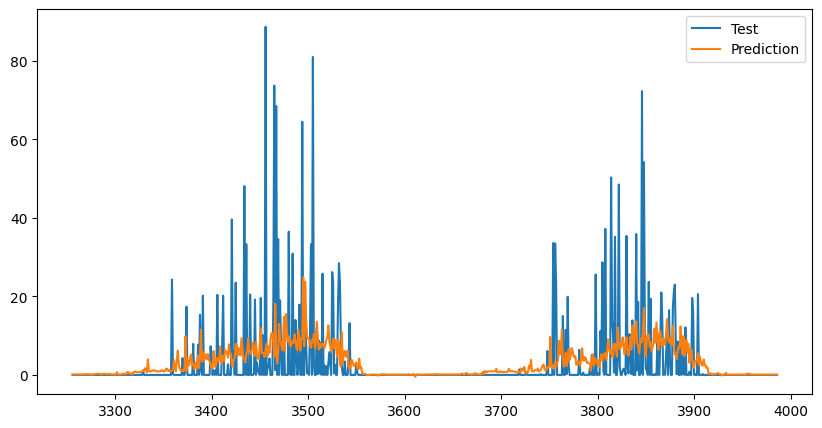

In [16]:
kd_model=model_final(Kandi_X_train,Kandi_y_train,Kandi_X_test,Kandi_y_test,3)

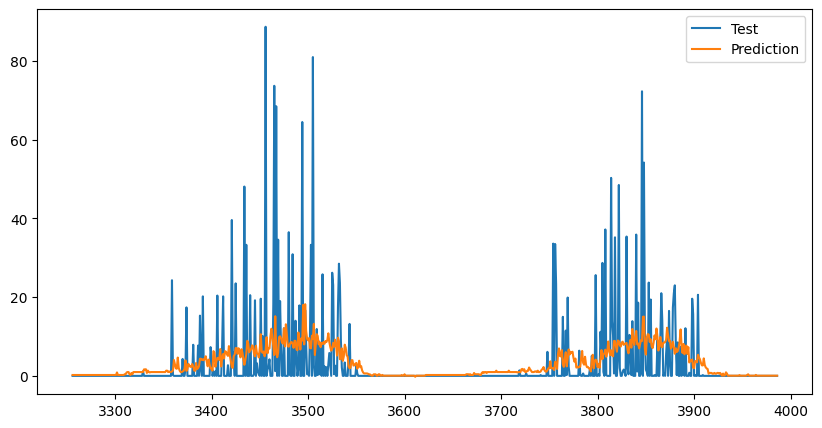

In [17]:
kd_model=model_final(Kandi_X_train,Kandi_y_train,Kandi_X_test,Kandi_y_test,2)

In [32]:
param={"n_estimators":range(50,250,50),
       "max_depth":[2,3,4,5,6,7,8],
       "learning_rate":[0.01,0.05,0.1,0.2,0.3,0.4,0.5],
         }

In [33]:
kd_grid=gridsech(Kandi_X_train,Kandi_y_train,Kandi_X_test,Kandi_y_test,param)

Fitting 5 folds for each of 196 candidates, totalling 980 fits
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.0s
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.0s
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.0s
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.1s
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.0s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.0s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.3s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.1s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.1s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.0s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=150; total time=   0.0s
[CV] END ..learning_rate=0.01, max_depth=2, n_

In [34]:
pk_grid=gridsech(Parakou_X_train,Parakou_y_train,Parakou_X_test,Parakou_y_test,param)

Fitting 5 folds for each of 196 candidates, totalling 980 fits
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.0s
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.0s
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.0s
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.0s
[CV] END ...learning_rate=0.01, max_depth=2, n_estimators=50; total time=   0.0s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.0s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.0s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.0s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.2s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=100; total time=   0.1s
[CV] END ..learning_rate=0.01, max_depth=2, n_estimators=150; total time=   0.1s
[CV] END ..learning_rate=0.01, max_depth=2, n_

In [35]:
kd_grid["grid"].best_params_

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}

In [36]:
pk_grid["grid"].best_params_

{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 50}

In [37]:
resultats_grid=pd.concat([pd.DataFrame({"Station":["Kandi"],"MAE":kd_grid["MAE"],"RMSE":kd_grid["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"MAE":pk_grid["MAE"],"RMSE":pk_grid["RMSE"]})],axis=0)

resultats_grid

,Station,MAE,RMSE
0,Kandi,4.363779,9.385307
0,Parakou,5.059537,11.089638


In [38]:
resultats_grid.to_csv("data//resultats_xgboost.csv",index=False)